In [2]:
import sys
import os
import scipy.ndimage as nd
import scipy.io as io
import numpy as np
import matplotlib.pyplot as plt
import skimage.measure as sk
from utils import utils

plt.style.use('ggplot')

In [3]:
from torch.autograd import Variable
from torchvision import datasets
from torchvision import transforms as tfs
from torch.utils import data

import torch
import PIL.ImageOps

In [4]:
available_device = "cuda" if torch.cuda.is_available() else "cpu"

In [5]:
from src.vasijas.reporting import ProcessingReport
from _bootstrap import setup
PATHS = setup()
report = ProcessingReport()

In [6]:
transformations = [tfs.RandomHorizontalFlip(p=0.7),
                   tfs.RandomAffine(0, scale=(0.7, 1.), fill=255),
                   tfs.RandomRotation((0, 360), fill=(255, 255, 255)),
                   tfs.Resize((128, 128))]

imagenet_data = datasets.ImageFolder(PATHS.DATA_FRACCIONES,
                                     transform=tfs.Compose(transformations))

data_loader = data.DataLoader(imagenet_data, batch_size=4, shuffle=True)

7038


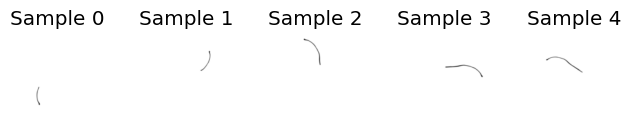

In [8]:
fig = plt.figure()

for i in range(len(imagenet_data)):

    sample = imagenet_data[i + 10]
    #print(sample)
    ax = plt.subplot(1, 5, i + 1)
    plt.tight_layout()
    plt.imshow(np.asarray(sample[0]), cmap=plt.cm.gray_r)
    ax.set_title('Sample {}'.format(i))
    ax.axis('off')

    if i == 4:
        plt.show()
        break